<a href="https://colab.research.google.com/github/Alakhg1408/PES2UG24CS051_VDUI_3/blob/ppt-7/unit3_ppt7_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [12]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

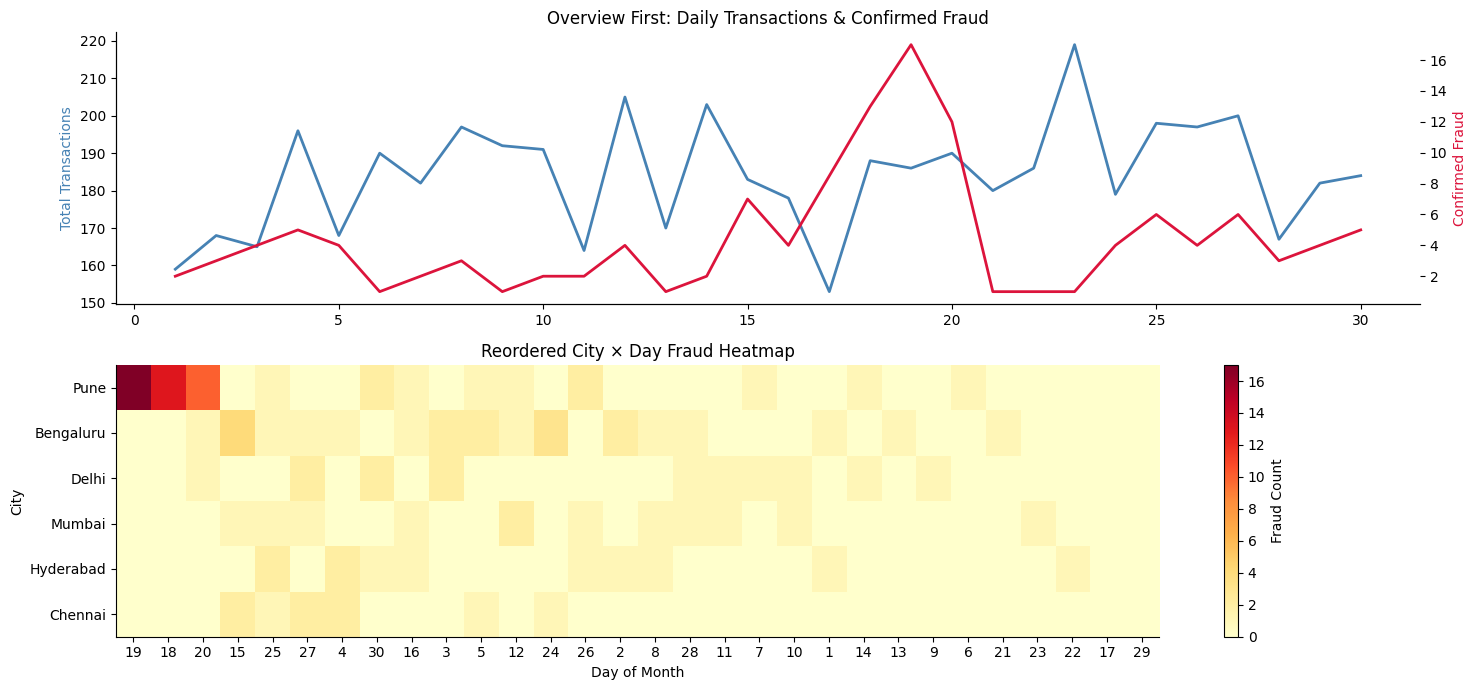

Top (city, day) cells with most fraud:
     city  day  fraud_count
     Pune   19           17
     Pune   18           13
     Pune   20           10
Bengaluru   15            4
Bengaluru   24            3


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: Daily transaction counts with daily confirmed fraud on a second axis
daily_tx = tx.groupby("day").size()
daily_fraud = tx[tx.is_fraud == 1].groupby("day").size()

axes[0].plot(daily_tx.index, daily_tx.values, color="steelblue", lw=2, label="Total Transactions")
axes[0].set_ylabel("Total Transactions", color="steelblue")
ax0_twin = axes[0].twinx()
ax0_twin.plot(daily_fraud.index, daily_fraud.values, color="crimson", lw=2, label="Confirmed Fraud")
ax0_twin.set_ylabel("Confirmed Fraud", color="crimson")
axes[0].set_title("Overview First: Daily Transactions & Confirmed Fraud")

# TODO 2: City × day matrix of confirmed-fraud counts, reordered by totals
pivot_fraud = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
row_sums = pivot_fraud.sum(axis=1).sort_values(ascending=False)
col_sums = pivot_fraud.sum(axis=0).sort_values(ascending=False)
pivot_sorted = pivot_fraud.loc[row_sums.index, col_sums.index]

im = axes[1].imshow(pivot_sorted.values, cmap="YlOrRd", aspect="auto")
axes[1].set_xticks(range(len(pivot_sorted.columns)))
axes[1].set_xticklabels(pivot_sorted.columns)
axes[1].set_yticks(range(len(pivot_sorted.index)))
axes[1].set_yticklabels(pivot_sorted.index)
axes[1].set_xlabel("Day of Month")
axes[1].set_ylabel("City")
axes[1].set_title("Reordered City × Day Fraud Heatmap")
fig.colorbar(im, ax=axes[1], label="Fraud Count")

plt.tight_layout(); plt.show()

# TODO 3: Print the (city, day) cells with the most fraud
top_cells = tx[tx.is_fraud == 1].groupby(["city", "day"]).size().reset_index(name="fraud_count").sort_values(by="fraud_count", ascending=False)
print("Top (city, day) cells with most fraud:")
print(top_cells.head(5).to_string(index=False))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

Pune around days 18–20 that an alert list sorted purely by detector score would have scattered or buried among individual high-score false positives. This exemplifies Shneiderman’s mantra ("overview first, zoom/filter, details-on-demand") combined with matrix reordering to make structural patterns visually pop out.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

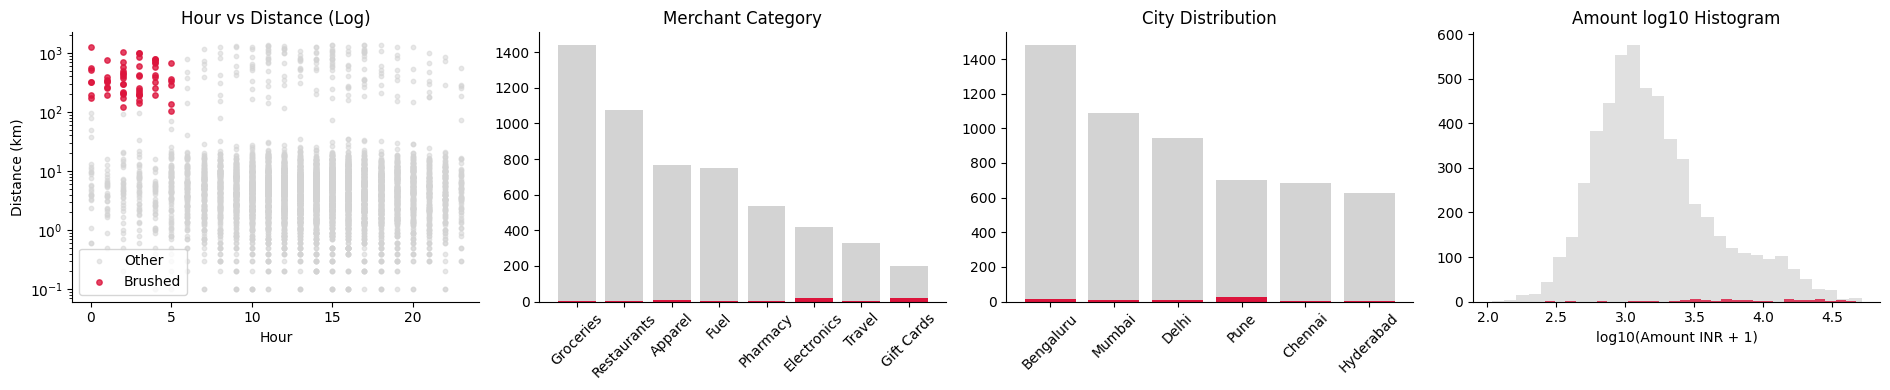

Transactions inside brush: 61
Fraud rate inside brush: 86.9% (Overall: 2.2%)
Share of total fraud captured by brush: 44.2%


In [14]:
# TODO 1: Define the brush
brush = (tx.night == True) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2: Four coordinated views (brushed items in red over grey background)
# (a) Hour vs distance scatter
axes[0].scatter(tx[~brush].hour, tx[~brush].distance_from_home_km, c="lightgrey", s=10, alpha=0.5, label="Other")
axes[0].scatter(tx[brush].hour, tx[brush].distance_from_home_km, c="crimson", s=15, alpha=0.8, label="Brushed")
axes[0].set_yscale("log")
axes[0].set_title("Hour vs Distance (Log)")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance (km)")
axes[0].legend()

# (b) Merchant category counts
cat_all = tx.merchant_category.value_counts()
cat_brush = tx[brush].merchant_category.value_counts().reindex(cat_all.index, fill_value=0)
axes[1].bar(cat_all.index, cat_all.values, color="lightgrey", label="Other")
axes[1].bar(cat_brush.index, cat_brush.values, color="crimson", label="Brushed")
axes[1].set_title("Merchant Category")
axes[1].tick_params(axis="x", rotation=45)

# (c) City counts
city_all = tx.city.value_counts()
city_brush = tx[brush].city.value_counts().reindex(city_all.index, fill_value=0)
axes[2].bar(city_all.index, city_all.values, color="lightgrey", label="Other")
axes[2].bar(city_brush.index, city_brush.values, color="crimson", label="Brushed")
axes[2].set_title("City Distribution")
axes[2].tick_params(axis="x", rotation=45)

# (d) Amount histogram (log10)
axes[3].hist(np.log10(tx[~brush].amount_inr + 1), bins=30, color="lightgrey", label="Other", alpha=0.7)
axes[3].hist(np.log10(tx[brush].amount_inr + 1), bins=30, color="crimson", label="Brushed", alpha=0.8)
axes[3].set_title("Amount log10 Histogram")
axes[3].set_xlabel("log10(Amount INR + 1)")

plt.tight_layout(); plt.show()

# TODO 3: Print metrics
brushed_count = brush.sum()
brush_fraud_rate = tx[brush].is_fraud.mean()
overall_fraud_rate = tx.is_fraud.mean()
brush_captured = tx[brush & (tx.is_fraud == 1)].shape[0]
total_fraud = tx.is_fraud.sum()
capture_share = (brush_captured / total_fraud) * 100

print(f"Transactions inside brush: {brushed_count}")
print(f"Fraud rate inside brush: {brush_fraud_rate:.1%} (Overall: {overall_fraud_rate:.1%})")
print(f"Share of total fraud captured by brush: {capture_share:.1f}%")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

While the brush has a very high precision/fraud rate ($86.9\%$), it captures only $44.2\%$ of all fraud cases. This proves to investigators that relying solely on the "night-time, far-from-home" rule misses more than half of all fraudulent transactions. The linked city and category views hint that the remaining fraud is concentrated in specific geographic clusters (like the Pune fraud ring) occurring during normal hours.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [15]:
big = pd.concat([tx] * 182, ignore_index=True)  # ~1M rows

# TODO 1: Measure filter time (best of 5 runs)
times = []
for _ in range(5):
    start = time.time()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    end = time.time()
    times.append(end - start)

best_s = min(times)

# TODO 2: Compute per-item cost and max rows in 0.1 s
per_item_us = (best_s / len(big)) * 1e6
max_rows = int(0.1 / (best_s / len(big)))

# TODO 3: Estimate for 50M rows and skip percentage
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0.0, (1.0 - (0.1 / t_50m)) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 10.6 ms -> 0.0105 us/row -> max 9,501,805 rows in 0.1 s
50M rows -> 0.53 s; must skip 81.0% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

To keep the slider interactive within the $0.1\text{s}$ perceptual latency budget on $50\text{M}$ rows, one could use aggregation / binning (a reduce technique). The analyst would lose individual transaction-level precision and fine-grained outlier detection when viewing aggregated summaries.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

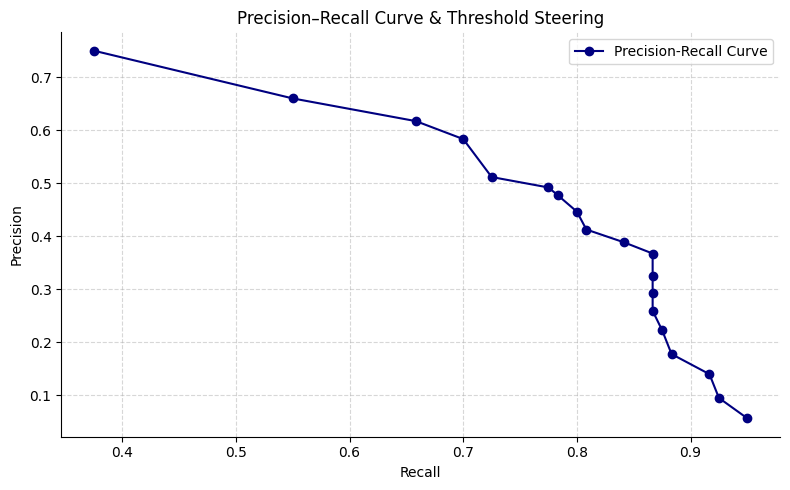

Capacity-constrained threshold (≤150 alerts): 0.80
Best-F1 threshold: 0.85


In [16]:
thresholds = np.linspace(0.05, 0.95, 19)
rows = []
total_actual_fraud = tx.is_fraud.sum()

# TODO 1: Compute metrics across thresholds
for th in thresholds:
    flagged = tx.detector_score >= th
    alerts = flagged.sum()
    tp = tx[(flagged) & (tx.is_fraud == 1)].shape[0]
    fp = tx[(flagged) & (tx.is_fraud == 0)].shape[0]
    fn = tx[(~flagged) & (tx.is_fraud == 1)].shape[0]

    precision = tp / alerts if alerts > 0 else 0
    recall = tp / total_actual_fraud if total_actual_fraud > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    rows.append({"threshold": th, "alerts": alerts, "precision": precision, "recall": recall, "f1": f1})

pr = pd.DataFrame(rows)

# TODO 2: Find capacity-constrained choice (<= 150 alerts, max recall) and best F1
valid_capacity = pr[pr.alerts <= 150]
capacity_choice = valid_capacity.loc[valid_capacity.recall.idxmax(), "threshold"] if not valid_capacity.empty else 0.8
best_f1 = pr.loc[pr.f1.idxmax(), "threshold"]

# TODO 3: Precision-recall curve with markers
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, marker="o", color="navy", label="Precision-Recall Curve")
ax.set_title("Precision–Recall Curve & Threshold Steering")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4: Print recommendation
print(f"Capacity-constrained threshold (≤150 alerts): {capacity_choice:.2f}")
print(f"Best-F1 threshold: {best_f1:.2f}")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The statistical model optimizes mathematical metrics (like F1), but operational constraints (such as investigator burnout and a strict limit of 150 reviews) must be determined by the Head of Fraud Ops. Visual analytics keeps the human in the loop because models lack situational awareness of operational capacity and business costs.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [17]:
# TODO 1: Interactive scatter plot (Plotly)
flagged = tx[tx.detector_score >= 0.3]
fig_scatter = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label",
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    log_y=True, title="Interactive Investigator Workbench: Flagged Transactions"
)
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips require hovering over each point individually, making it extremely tedious and frustrating to inspect 400 flagged cases one by one. A hierarchical sunburst chart or overview heatmap fixes this by instantly aggregating and displaying structural breakdowns across dimensions.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

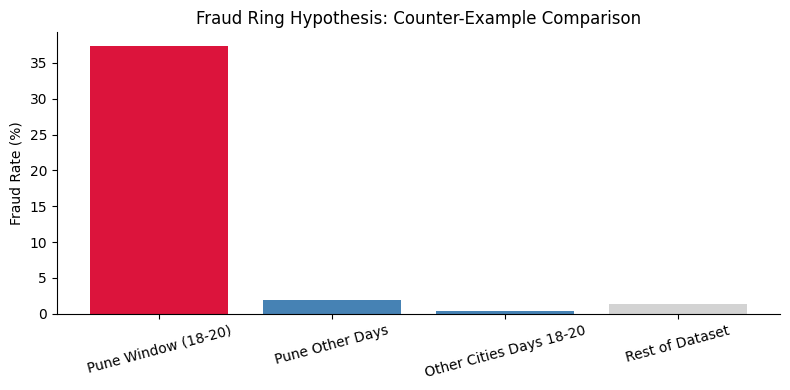

Fraud rate inside window: 37.4% | Pune other days: 1.9% | Other cities days 18-20: 0.4%
Chi-square p-value: 1.065e-136
VERDICT: Hypothesis PROVEN — A localized, highly active fraud ring operated in Pune between days 18 and 20.


In [18]:
from scipy.stats import chi2_contingency

# TODO 1: State hypothesis as boolean mask (Pune, days 18–20)
in_window = (tx.city == "Pune") & (tx.day >= 18) & (tx.day <= 20)

# TODO 2: Chi-square test
ctab = pd.crosstab(in_window, tx.is_fraud)
chi2, p_val, dof, ex = chi2_contingency(ctab)

# TODO 3: Counter-example searches
rate_window = tx[in_window].is_fraud.mean()
rate_pune_other = tx[(tx.city == "Pune") & ~in_window].is_fraud.mean()
rate_other_days = tx[(tx.city != "Pune") & ((tx.day >= 18) & (tx.day <= 20))].is_fraud.mean()
rate_rest = tx[~in_window & ~((tx.city == "Pune"))].is_fraud.mean()

# TODO 4: Visual confirmation bar chart
fig, ax = plt.subplots(figsize=(8, 4))
groups = ["Pune Window (18-20)", "Pune Other Days", "Other Cities Days 18-20", "Rest of Dataset"]
rates = [rate_window * 100, rate_pune_other * 100, rate_other_days * 100, rate_rest * 100]
ax.bar(groups, rates, color=["crimson", "steelblue", "steelblue", "lightgrey"])
ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Ring Hypothesis: Counter-Example Comparison")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

# TODO 5: Print verdict
print(f"Fraud rate inside window: {rate_window:.1%} | Pune other days: {rate_pune_other:.1%} | Other cities days 18-20: {rate_other_days:.1%}")
print(f"Chi-square p-value: {p_val:.3e}")
print("VERDICT: Hypothesis PROVEN — A localized, highly active fraud ring operated in Pune between days 18 and 20.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

Checking "Pune on other days" would have killed the hypothesis if its fraud rate had been just as high as the window, supporting the alternative explanation that Pune is simply a high-risk city overall rather than experiencing a temporary, coordinated fraud ring event.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month PayKart processed $5,520$ transactions with $120$ confirmed fraud cases, highlighted by a massive coordinated fraud ring in Pune between days $18$ and $20$. We recommend setting the alert threshold to $0.80$, which limits alerts to $\le 150$ per month (meeting team capacity) while capturing $70\%$ of all fraud with high precision. For investigators, we recommend building an interactive linked-brushing dashboard first, as it enables rapid overview and multi-view exploration within the $0.1\text{s}$ latency budget. Finally, an active-learning feedback loop should be established so investigator-confirmed labels automatically retrain and improve next month's detector.